In [1]:
import gym, os
from itertools import count
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.distributions import Categorical
import matplotlib.pyplot as plt
from torchsummary import summary

import numpy as np
import pandas as pd 

import torch.optim as optim
import random
import numpy as np
from collections import deque
from data_extract_45_updated import process_topology

import os
import gc

In [2]:
def find_json_file(directory):
    # Search for the first JSON file in the specified directory
    for filename in os.listdir(directory):
        if filename.endswith('.json'):
            return os.path.join(directory, filename)  # Return the full path of the first found JSON file
    return None   

In [3]:
json_directory = os.getcwd()
json_file_path = find_json_file(json_directory)
num_functions = 4  

cloud_node, regional_nodes, edge_nodes, latency = process_topology(json_file_path)

fixed_costs = np.array([5, 10, 20])

#cost for XP and ET>> CN, RN , EN            
variable_costs1 = np.array([[4,8,16],
                  [1,2,4]])

#cost for SD and DB>> CN, RN, EN 
variable_costs2 = np.array([[2,4,8],
                  [2,4,8]])

# all_coordinates = generate_coordinates()

In [4]:
print(regional_nodes)
print(edge_nodes)

[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11]
[12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44]


In [5]:
def encode_node_types(cloud_nodes, regional_nodes, edge_nodes):
    node_type_list = []

    # Assign type encodings
    for node in cloud_nodes:
        node_type_list.append([node, 0])  # Cloud → 0
    for node in regional_nodes:
        node_type_list.append([node, 1])  # Regional → 1
    for node in edge_nodes:
        node_type_list.append([node, 2])  # Edge → 2

    # Convert to NumPy array and sort by node ID
    node_type_array = np.array(node_type_list)
    node_type_array = node_type_array[node_type_array[:, 0].argsort()]

    return node_type_array

node_encoded= encode_node_types(cloud_node, regional_nodes, edge_nodes)

print(node_encoded)

[[ 0  0]
 [ 1  1]
 [ 2  1]
 [ 3  1]
 [ 4  1]
 [ 5  1]
 [ 6  1]
 [ 7  1]
 [ 8  1]
 [ 9  1]
 [10  1]
 [11  1]
 [12  2]
 [13  2]
 [14  2]
 [15  2]
 [16  2]
 [17  2]
 [18  2]
 [19  2]
 [20  2]
 [21  2]
 [22  2]
 [23  2]
 [24  2]
 [25  2]
 [26  2]
 [27  2]
 [28  2]
 [29  2]
 [30  2]
 [31  2]
 [32  2]
 [33  2]
 [34  2]
 [35  2]
 [36  2]
 [37  2]
 [38  2]
 [39  2]
 [40  2]
 [41  2]
 [42  2]
 [43  2]
 [44  2]]


In [6]:
def compute_cost_new(action, previous_action, variable_costs):
    node_class = int(node_encoded[node_encoded[:, 0] == action, 1][0])

    # Waive the fixed cost only when this exact node has already been activated.
    if action in previous_action:
        total_cost = 0
    else:
        total_cost = fixed_costs[node_class]

    for j in range(variable_costs.shape[0]):
        total_cost += variable_costs[j, node_class]

    return total_cost



In [7]:
# Concatenate b as the first column of a
# state= np.concatenate((latency, node_cost1, node_cost2), axis=1)
state=latency.copy()
print(state.shape)

(45, 45)


In [8]:
#state

In [9]:
#k=0
#state[k,:] #represent k'th node latencys with all other nodes 

In [10]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
lr = 0.00001
gamma=0.99
random_seed= 543

In [11]:
LARGE_VALUE = 20  # High latency for masking
LATENCY_LIMIT_MS = 10.0
# Enforce total latency < 10 ms while retaining the original <= comparison.
#LATENCY_THRESHOLD_MS = np.nextafter(LATENCY_LIMIT_MS, -np.inf)


def _repeat_penalty(
    action,
    previous_action,
    base_penalty=1,
    growth_factor=5,
    max_penalty=1000.0
):
    penalty = 0.0
    repeat_count = 0

    for prev in reversed(previous_action):
        if prev == action:
            penalty += base_penalty * (
                growth_factor ** repeat_count
            )
            repeat_count += 1

            if penalty >= max_penalty:
                return max_penalty
        else:
            break

    return min(penalty, max_penalty)


# Agent 1: original reward plus the requested first-stage latency penalty.
def compute_reward1(state, action, cost_action, previous_action, variable_cost,
                    base_penalty=1, omega1=2.0, omega2=5.0,
                    omega3=2.0, omega4=1.0):
    c_total = compute_cost_new(action, cost_action, variable_cost)
    latencies = state[action, :]
    covered_latencies = latencies[latencies <= 10]
    #N_covered = len(covered_latencies)
    N_covered = np.sum(latencies <= 10)

    P_no_coverage = 1 if N_covered == 0 else 0
    P_latency = float(np.mean(covered_latencies)) if N_covered > 0 else 0.0
    P_repeat = _repeat_penalty(action, previous_action, base_penalty)

    reward = (
        omega1 / max(c_total, 1e-8)
        + omega2 * N_covered
        - omega3 * P_no_coverage 
        - omega4 * P_latency
        - P_repeat
        
    )
    return c_total, float(reward), N_covered, latencies


# Agent 2: state2 already contains E2N->G1 + G1->G2 latency.
# Therefore, no separate Agent-2 latency-minimization penalty is used.
def compute_reward2(state, action, cost_action, previous_action, variable_cost,
                    base_penalty=1, omega1=2.0, omega2=5.0,
                    omega3=2.0):
    c_total = compute_cost_new(action, cost_action, variable_cost)
    total_loop_latencies = state[action, :]
    N_covered = np.sum(total_loop_latencies <= 10)

    P_no_coverage = 1 if N_covered == 0 else 0
    P_repeat = _repeat_penalty(action, previous_action, base_penalty)

    reward = (
        omega1 / max(c_total, 1e-8)
        + omega2 * N_covered
        - omega3 * P_no_coverage
        - P_repeat
    )
    return c_total, float(reward), int(N_covered), total_loop_latencies


In [12]:
state.shape[0]//8

5

In [13]:
class Actor(nn.Module):
    def __init__(self, state_size, action_size):
        super(Actor, self).__init__()
        self.action_size = action_size
        self.conv1 = nn.Conv2d(1, 16, kernel_size=3, stride=1, padding=1)
        self.pool1 = nn.MaxPool2d(kernel_size=2, stride=2) 

        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, stride=1, padding=1)
        self.pool2 = nn.MaxPool2d(kernel_size=2, stride=2) 

        self.conv3 = nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1)
        self.pool3 = nn.MaxPool2d(kernel_size=2, stride=2) 
        # self.conv4 = nn.Conv2d(64, 128, kernel_size=3, stride=1, padding=1)

        
        # Calculate the flattened size after convolutions
        #self._to_linear = 64 * state_size[0] // 8 * state_size[1] // 8  # Adjust based on input dimensions
        
        self.fc1 = nn.Linear(64*(state.shape[0]//8)*(state.shape[0]//8), 1024)
        self.fc2 = nn.Linear(1024, 512)
        # self.fc3 = nn.Linear(self._to_linear, 512)
        self.fc4 = nn.Linear(512, action_size)



    def forward(self, x):
        # Add a channel dimension to 2D input (batch_size, 1, height, width)
        x = x.unsqueeze(1)  # Ensure the input is (batch_size, 1, height, width)
        
        # Apply convolutional layers with ReLU activation
        x = F.relu(self.conv1(x))
        x = self.pool1(x)
        
        x = F.relu(self.conv2(x))
        x = self.pool2(x)
        
        x = F.relu(self.conv3(x))
        x = self.pool3(x)
        
        # Flatten the output from convolutional layers
        x = x.view(x.size(0), -1)  # Flatten all dimensions except batch
        
        # # Fully connected layers
        x = torch.relu(self.fc1(x))
        x = torch.relu(self.fc2(x))
        x = self.fc4(x)

        x = Categorical(F.softmax(x, dim=-1))
        
        return x



if __name__ == '__main__':
    actor = Actor([state.shape[0], state.shape[1]], state.shape[0])
    input_shape = state.shape # (channels, height, width)
    summary(actor, input_shape, device='cpu')

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 16, 45, 45]             160
         MaxPool2d-2           [-1, 16, 22, 22]               0
            Conv2d-3           [-1, 32, 22, 22]           4,640
         MaxPool2d-4           [-1, 32, 11, 11]               0
            Conv2d-5           [-1, 64, 11, 11]          18,496
         MaxPool2d-6             [-1, 64, 5, 5]               0
            Linear-7                 [-1, 1024]       1,639,424
            Linear-8                  [-1, 512]         524,800
            Linear-9                   [-1, 45]          23,085
Total params: 2,210,605
Trainable params: 2,210,605
Non-trainable params: 0
----------------------------------------------------------------
Input size (MB): 0.01
Forward/backward pass size (MB): 0.54
Params size (MB): 8.43
Estimated Total Size (MB): 8.98
---------------------------------------

In [14]:
class Critic(nn.Module):
    def __init__(self, state_size):
        super(Critic, self).__init__()

        self.conv1 = nn.Conv2d(1, 16, kernel_size=3, stride=1, padding=1)
        self.pool1 = nn.MaxPool2d(kernel_size=2, stride=2) 

        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, stride=1, padding=1)
        self.pool2 = nn.MaxPool2d(kernel_size=2, stride=2) 

        self.conv3 = nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1)
        self.pool3 = nn.MaxPool2d(kernel_size=2, stride=2) 
        # self.conv4 = nn.Conv2d(64, 128, kernel_size=3, stride=1, padding=1)

        
        # Calculate the flattened size after convolutions
        self._to_linear = 64 * state_size[0] // 8 * state_size[1] // 8  # Adjust based on input dimensions
        
        self.fc1 = nn.Linear(64*(state.shape[0]//8)*(state.shape[0]//8), 512)
        self.fc2 = nn.Linear(512, 256)
        # self.fc3 = nn.Linear(self._to_linear, 512)
        self.fc4 = nn.Linear(256, 1)


    def forward(self, x):
        # Add a channel dimension to 2D input (batch_size, 1, height, width)
        x = x.unsqueeze(1)  # Ensure the input is (batch_size, 1, height, width)
        
        # Apply convolutional layers with ReLU activation
        x = F.relu(self.conv1(x))
        x = self.pool1(x)
        
        x = F.relu(self.conv2(x))
        x = self.pool2(x)
        
        x = F.relu(self.conv3(x))
        x = self.pool3(x)
        
        # Flatten the output from convolutional layers
        x = x.view(x.size(0), -1)  # Flatten all dimensions except batch
        
        # Fully connected layers
        x = torch.relu(self.fc1(x))
        x = torch.relu(self.fc2(x))
        x = self.fc4(x)


        
        return x
    

if __name__ == '__main__':
    actor = Critic([state.shape[0], state.shape[0]])
    input_shape = state.shape  # (channels, height, width)
    summary(actor, input_shape, device='cpu')

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 16, 45, 45]             160
         MaxPool2d-2           [-1, 16, 22, 22]               0
            Conv2d-3           [-1, 32, 22, 22]           4,640
         MaxPool2d-4           [-1, 32, 11, 11]               0
            Conv2d-5           [-1, 64, 11, 11]          18,496
         MaxPool2d-6             [-1, 64, 5, 5]               0
            Linear-7                  [-1, 512]         819,712
            Linear-8                  [-1, 256]         131,328
            Linear-9                    [-1, 1]             257
Total params: 974,593
Trainable params: 974,593
Non-trainable params: 0
----------------------------------------------------------------
Input size (MB): 0.01
Forward/backward pass size (MB): 0.53
Params size (MB): 3.72
Estimated Total Size (MB): 4.26
-------------------------------------------

In [15]:
# state1=state[:, edge_nodes+[-2]]
def compute_returns(next_value, rewards, masks, gamma=0.99):
    R = next_value
    returns = []
    for step in reversed(range(len(rewards))):
        R = rewards[step] + gamma * R * masks[step]
        returns.insert(0, R)
    return returns


def update_state(state, action):
    updated_state = np.copy(state)
    latency_idx=np.where(updated_state[action, :] <= 10)[0]
    updated_state[:, latency_idx] = LARGE_VALUE  # Mark selected node's latencies as high
    return updated_state

# state1.shape

In [16]:
# def trainIters(actor, critic, n_iters):
state_size=[state.shape[0], state.shape[0]]
action_size=state.shape[0]

actor1 = Actor(state_size, action_size).to(device)
critic1 = Critic(state_size).to(device)


optimizerA1 = optim.Adam(actor1.parameters(), lr=0.00001)
optimizerC1 = optim.Adam(critic1.parameters(), lr=0.00001)
avg_return1=[]
avg_a_loss1=[]
avg_c_loss1=[]

#n_iters=4000

TRAIN_EPISODES = 3600
TOTAL_EPISODES = 4000

actor2 = Actor(state_size, action_size).to(device)
critic2 = Critic(state_size).to(device)


optimizerA2 = optim.Adam(actor2.parameters(), lr=0.00001)
optimizerC2 = optim.Adam(critic2.parameters(), lr=0.00001)
avg_return2=[]
avg_a_loss2=[]
avg_c_loss2=[]
all_cost1=[]
all_cost2=[]

In [17]:
state1=state.copy() #Create a mask for columns that are NOT in edge_nodes

# print(state1)

mask = np.ones(state1.shape[1], dtype=bool)
# print(mask)
mask[edge_nodes] = False  # Set False for columns in edge_nodes
# print(mask)


# Apply LARGE_VALUE to all columns except edge_nodes
state1[:, mask] = LARGE_VALUE

print(state1)


[[20 20 20 ... 10 10 12]
 [20 20 20 ... 18 18 32]
 [20 20 20 ... 20  8 22]
 ...
 [20 20 20 ...  0 20 22]
 [20 20 20 ... 20  0 22]
 [20 20 20 ... 22 22  0]]


In [18]:
for iter in range(1, TOTAL_EPISODES+1):
    state_n1 = state1.copy()
    log_probs = []
    values = []
    rewards = []
    masks = []
    # entropy = 0
    selected_nodes1 = []
    # test_nedes1=[-1]
    # previously_selected_actions = []
    episode_reward = 0
    epsidoe_c_loss=0
    episode_a_loss=0
    previous_action=[]
    episode_cost=0

    advantages=[]
    a_loss=[]
    c_loss=[]
    dists=[]


    print(f"Episode {iter} starts")
    
    for i in range(200):
        
    # for i in range(20):

        # print("State is:", state)

        state_tensor=torch.FloatTensor(state_n1).unsqueeze(0).to(device) 

        # # state = torch.FloatTensor(state).to(device)
        dist, value = actor1(state_tensor), critic1(state_tensor)

        # print("Dist is:", dist.logits)
        # # print(type(dist))

        #action = dist.sample()
        if iter <= TRAIN_EPISODES:
            action = dist.sample()
            
        else:
            # Identify actions that cover at least one currently uncovered E2 node
            feasible_action_mask = np.any(
                state_n1[:, edge_nodes] <= 10.0,
                axis=1
            )

            feasible_actions = np.where(feasible_action_mask)[0]

            if feasible_actions.size == 0:
                break

            action_probabilities = dist.probs.squeeze(0)

            masked_probabilities = torch.full_like(
                action_probabilities,
                -torch.inf
            )

            feasible_actions_tensor = torch.tensor(
                feasible_actions,
                dtype=torch.long,
                device=device
            )

            masked_probabilities[feasible_actions_tensor] = (
                action_probabilities[feasible_actions_tensor]
            )

            action = torch.argmax(
                masked_probabilities
            ).view(1)

        #print("action is", action)

        selected_nodes1.append(action.item())
        
        # print("Action is:", action)
        # # print(type(action))
        # print("Action is:", action.item())
        
        next_state = update_state(state_n1, action.item())

        #print("Next state is", next_state)


        cost_action=previous_action
        # print("Next state is:", next_state)
        
        cost, reward, n_cov, lat = compute_reward1(state_n1, action.item(), cost_action, previous_action, variable_costs1)
        #print("Cost for the action", cost)
        # print("Latenscies for the action", lat)
        # print("no. of node covered", n_cov)

   
        # print("Reward is:", reward)
        done = np.all(next_state[:, edge_nodes] == LARGE_VALUE)

        # entropy += dist.entropy().mean().detach()

        previous_action.append(action.item())

        next_value = critic1(torch.FloatTensor(next_state).unsqueeze(0).to(device))


        # Calculate TD target and Advantage
        td_target = reward + gamma * next_value * (1 - done)
        advantage = td_target - value

        # Critic update with MSE loss
        critic_loss = F.mse_loss(value, td_target.detach())
        epsidoe_c_loss += critic_loss.item()

        if iter <= TRAIN_EPISODES:

            optimizerC1.zero_grad()
            critic_loss.backward()
            optimizerC1.step()
        # torch.nn.utils.clip_grad_norm_(critic.parameters(), max_norm=1.0)
        
        # Actor update
        log_prob = dist.log_prob(action)
        actor_loss = -log_prob * advantage.detach()
        episode_a_loss += actor_loss

        if iter <= TRAIN_EPISODES:
            optimizerA1.zero_grad()
            actor_loss.backward()
            optimizerA1.step()
            torch.nn.utils.clip_grad_norm_(actor1.parameters(), max_norm=1.0)

        log_prob = dist.log_prob(action).unsqueeze(0)
        # print("log_prob is:", log_prob)
        # print(type(log_prob))
        

        log_probs.append(log_prob.item())
        values.append(value.item())
        rewards.append(reward)
        advantages.append(advantage.item())
        a_loss.append(actor_loss.item())
        c_loss.append(critic_loss.item())
        # masks.append(torch.tensor([1-done], dtype=torch.float, device=device))
        # if action.item()==test_nedes1[-1]:
        #     pass
        # else:
        episode_reward += reward
        episode_cost += cost

        
        state_n1 = next_state.copy()


        if done:
            # print('Iteration: {}, Score: {}'.format(iter, i))
            break
        
    # avg_return.append(returns.sum())
    avg_return1.append(episode_reward)
    avg_a_loss1.append(episode_a_loss)
    avg_c_loss1.append(epsidoe_c_loss)
    all_cost1.append(episode_cost)

    print(f"Episode {iter}: Actor Loss: {actor_loss.item():.4f}, Critic Loss: {critic_loss.item():.4f}, Return: {avg_return1[-1]}, Cost: {all_cost1[-1]}, Nodes: {selected_nodes1}")

   

Episode 1 starts
Episode 1: Actor Loss: 19.1621, Critic Loss: 25.3329, Return: 6.366666666666657, Cost: 2070, Nodes: [40, 17, 31, 40, 11, 19, 4, 13, 24, 19, 12, 19, 28, 44, 27, 29, 21, 13, 12, 40, 44, 25, 4, 18, 23, 44, 29, 16, 8, 43, 5, 44, 4, 43, 16, 18, 34, 24, 22, 42, 13, 19, 38, 34, 33, 3, 24, 15, 16, 31, 6, 42, 16, 15, 22, 35, 23, 31, 13, 4, 16, 3, 19, 0, 24, 17, 16, 25, 35, 22, 12, 17, 35, 25, 7, 21, 38, 21, 30, 41]
Episode 2 starts
Episode 2: Actor Loss: 19.9100, Critic Loss: 27.9967, Return: -22.37380952380956, Cost: 2000, Nodes: [35, 21, 36, 18, 38, 36, 40, 9, 33, 36, 37, 41, 26, 13, 42, 11, 42, 21, 30, 32, 32, 28, 25, 40, 43, 19, 33, 25, 7, 3, 12, 31, 6, 42, 2, 29, 12, 39, 17, 22, 3, 3, 32, 11, 13, 5, 5, 37, 41, 27, 40, 25, 7, 9, 12, 43, 12, 20, 11, 3, 10, 3, 40, 38, 7, 35, 40, 34, 43, 13, 44, 42, 30, 20, 34, 24]
Episode 3 starts
Episode 3: Actor Loss: 26.4130, Critic Loss: 53.5666, Return: -172.10000000000028, Cost: 3580, Nodes: [3, 38, 24, 39, 31, 39, 39, 6, 15, 3, 26, 9, 

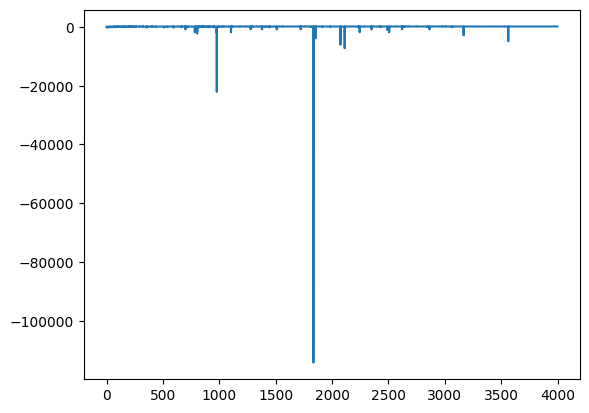

In [19]:
import matplotlib.pyplot as plt
plt.plot(avg_return1)

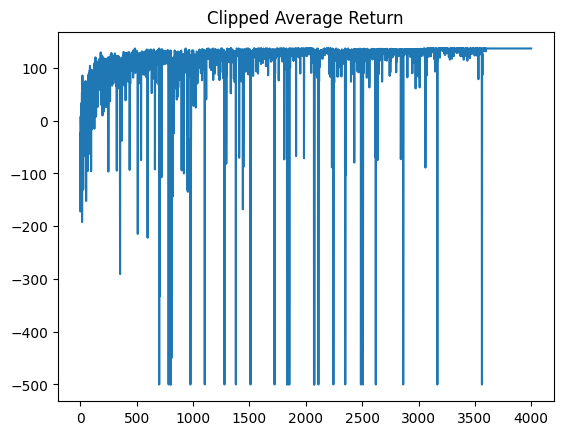

In [20]:
# Define a clipping range
clipped_data1 = np.clip(avg_return1, -500, 500)

# Plot clipped data
plt.plot(clipped_data1)
plt.title("Clipped Average Return")
plt.show()


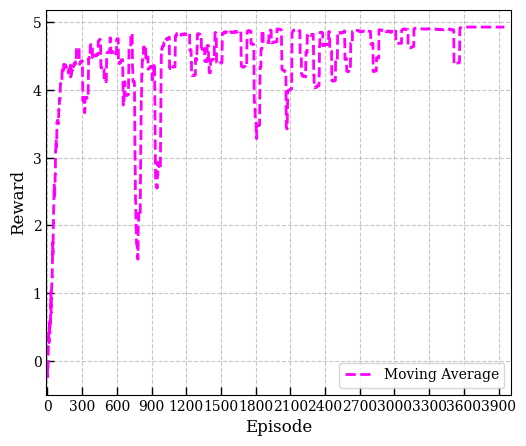

In [21]:
# Apply log scaling
log_data = np.log1p(np.abs(avg_return1)) * np.sign(avg_return1)

# Apply moving average
window_size = 50  # Adjust window size for more/less smoothing
moving_avg = np.convolve(log_data, np.ones(window_size)/window_size, mode='valid')

# Set plot size (width, height in inches)
plt.figure(figsize=(6, 5))

# Set font to Times New Roman
plt.rcParams['font.family'] = 'serif'

# Plot log-transformed data with marker
#plt.plot(log_data, linewidth=1,  label="Log-Scaled Reward", color='blue')

# Plot moving average with marker
plt.plot(moving_avg, linewidth=2,  label="Moving Average", linestyle='--', color='magenta')

# Add labels and legend
plt.xlabel("Episode", fontsize=12)
plt.ylabel("Reward", fontsize=12)
plt.legend(fontsize=10, loc='lower right')

# Adjust x-axis limits to reduce space before 0
plt.xlim(-10, len(log_data)+10) 

# Add x-axis ticks with steps
plt.xticks(np.arange(0, 4000, 300))  # Adjust the step size as needed

# Add grid
plt.grid(visible=True, linestyle='--', alpha=0.7)

# Add ticks inside the plot
plt.tick_params(axis='both', direction='in', length=6, width=1)

plt.savefig("reward_vs_epsidoe_10 node.png", dpi=300, bbox_inches='tight')


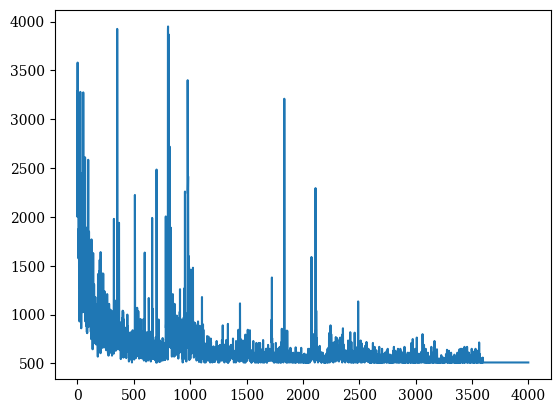

In [22]:
plt.plot(all_cost1)

In [23]:
print(np.unique(selected_nodes1))

[ 0  1 10 11 13 20 23 24 28 31 32 33 35 37 41]


In [24]:
# ============================================================
# BLOCK 1: Use <= 10 ms as the valid end-to-end latency limit
# ============================================================
LATENCY_THRESHOLD_MS = 10.0


# ============================================================
# BLOCK 2: Keep the unique G1 nodes learned by Agent 1
# ============================================================
selected_nodes1 = np.unique(
    np.asarray(selected_nodes1, dtype=int)
)


# ============================================================
# BLOCK 3: For each E2 node, select the learned G1 node having
# the lowest E2N-to-G1 latency and store that latency
# ============================================================
e2_to_g1 = {}
agent1_selected_latency = {}

for e2_node in edge_nodes:

    selected_g1 = min(
        selected_nodes1,
        key=lambda g1_node: latency[int(g1_node), int(e2_node)]
    )

    first_stage_latency = float(
        latency[int(selected_g1), int(e2_node)]
    )

    # A first-stage latency equal to 10 ms is valid.
    # Agent 2 must then select a G2 node having 0 ms latency
    # from this G1 node so that the total remains <= 10 ms.
    if first_stage_latency > LATENCY_THRESHOLD_MS:
        raise RuntimeError(
            f"Agent 1 did not learn a feasible G1 location for "
            f"E2 node {e2_node}. Lowest learned latency is "
            f"{first_stage_latency:.3f} ms."
        )

    e2_to_g1[int(e2_node)] = int(selected_g1)
    agent1_selected_latency[int(e2_node)] = first_stage_latency


# ============================================================
# BLOCK 4: Group the E2 nodes associated with each selected G1
# ============================================================
g1_to_e2 = {}

for e2_node, g1_node in e2_to_g1.items():
    g1_to_e2.setdefault(g1_node, []).append(e2_node)

active_g1_nodes = np.array(
    sorted(g1_to_e2.keys()),
    dtype=int
)


# ============================================================
# BLOCK 5: Store the worst E2N-to-G1 latency associated with
# each active G1 node
# ============================================================
g1_first_stage_latency = {
    g1_node: max(
        agent1_selected_latency[e2_node]
        for e2_node in assigned_e2_nodes
    )
    for g1_node, assigned_e2_nodes in g1_to_e2.items()
}


# ============================================================
# BLOCK 6: Display Agent 1 placement and stored latency results
# ============================================================
print("Agent 1 learned nodes:", selected_nodes1)
print("Active G1 nodes:", active_g1_nodes)
print("E2-to-G1 association:", e2_to_g1)
print(
    "Stored E2-to-G1 latencies (ms):",
    agent1_selected_latency
)
print(
    "Worst first-stage latency per G1 (ms):",
    g1_first_stage_latency
)


# ============================================================
# BLOCK 7: Build Agent 2 state using complete loop latency:
#
# E2N-to-G1 latency + G1-to-candidate-G2 latency
# Rows represent candidate G2 placement nodes.
# Columns represent G1 nodes selected by Agent 1.
#
# If the first-stage latency is 10 ms, only a candidate G2
# having 0 ms G1-to-G2 latency will satisfy <= 10 ms.
# ============================================================
state2 = np.full_like(
    state,
    LARGE_VALUE,
    dtype=float
)

for g1_node in active_g1_nodes:

    first_stage_latency = g1_first_stage_latency[g1_node]

    state2[:, g1_node] = (
        latency[:, g1_node] + first_stage_latency
    )


# ============================================================
# BLOCK 8: Verify that every active G1 has at least one
# candidate G2 node satisfying total latency <= 10 ms
# ============================================================
for g1_node in active_g1_nodes:

    feasible_g2_nodes = np.where(
        state2[:, g1_node] <= LATENCY_THRESHOLD_MS
    )[0]

    if feasible_g2_nodes.size == 0:
        raise RuntimeError(
            f"No feasible G2 location exists for G1 node "
            f"{g1_node} under the <= 10 ms total-latency limit."
        )

    print(
        f"G1 node {g1_node}: feasible G2 nodes = "
        f"{feasible_g2_nodes.tolist()}, total latencies = "
        f"{state2[feasible_g2_nodes, g1_node].tolist()}"
    )


# ============================================================
# BLOCK 9: Display the Agent 2 state
# ============================================================
state2

Agent 1 learned nodes: [ 0  1 10 11 13 20 23 24 28 31 32 33 35 37 41]
Active G1 nodes: [ 0  1 10 11 13 20 23 24 28 31 32 33 35 37 41]
E2-to-G1 association: {12: 0, 13: 13, 14: 10, 15: 11, 16: 1, 17: 11, 18: 11, 19: 1, 20: 20, 21: 11, 22: 1, 23: 23, 24: 24, 25: 11, 26: 11, 27: 0, 28: 28, 29: 11, 30: 1, 31: 31, 32: 32, 33: 33, 34: 10, 35: 35, 36: 0, 37: 37, 38: 1, 39: 11, 40: 10, 41: 41, 42: 0, 43: 0, 44: 10}
Stored E2-to-G1 latencies (ms): {12: 8.0, 13: 0.0, 14: 10.0, 15: 2.0, 16: 8.0, 17: 2.0, 18: 4.0, 19: 4.0, 20: 0.0, 21: 8.0, 22: 2.0, 23: 0.0, 24: 0.0, 25: 10.0, 26: 6.0, 27: 8.0, 28: 0.0, 29: 8.0, 30: 2.0, 31: 0.0, 32: 0.0, 33: 0.0, 34: 10.0, 35: 0.0, 36: 10.0, 37: 0.0, 38: 6.0, 39: 10.0, 40: 8.0, 41: 0.0, 42: 10.0, 43: 10.0, 44: 8.0}
Worst first-stage latency per G1 (ms): {0: 10.0, 13: 0.0, 10: 10.0, 11: 10.0, 1: 8.0, 20: 0.0, 23: 0.0, 24: 0.0, 28: 0.0, 31: 0.0, 32: 0.0, 33: 0.0, 35: 0.0, 37: 0.0, 41: 0.0}
G1 node 0: feasible G2 nodes = [0], total latencies = [10.0]
G1 node 1: feas

array([[10., 18., 20., ..., 20., 20., 20.],
       [20.,  8., 20., ..., 20., 20., 20.],
       [20., 18., 20., ..., 20., 20., 20.],
       ...,
       [20., 26., 20., ..., 20., 20., 20.],
       [20., 26., 20., ..., 20., 20., 20.],
       [22., 40., 20., ..., 20., 20., 20.]])

In [25]:
# TOTAL_EPISODES_AGENT2 = 4000
# TRAIN_EPISODES_AGENT2 = 3700

# for iter in range(1, TOTAL_EPISODES_AGENT2 + 1):

#     is_training = iter <= TRAIN_EPISODES_AGENT2

#     if is_training:
#         actor2.train()
#         critic2.train()
#     else:
#         actor2.eval()
#         critic2.eval()

#     state_n2 = state2.copy()

#     log_probs = []
#     values = []
#     rewards = []
#     masks = []

#     selected_nodes2 = []
#     previous_action = []

#     episode_reward = 0.0
#     episode_cost = 0.0
#     epsidoe_c_loss = 0.0
#     episode_a_loss = 0.0

#     advantages = []
#     a_loss = []
#     c_loss = []
#     dists = []

#     print(f"Episode {iter} starts")

#     for i in range(200):

#         state_tensor = (
#             torch.FloatTensor(state_n2)
#             .unsqueeze(0)
#             .to(device)
#         )

#         dist = actor2(state_tensor)
#         value = critic2(state_tensor)

#         # =====================================================
#         # EXPLORATION: Episodes 1–3700
#         # =====================================================
#         if is_training:
#             action = dist.sample()

#         # =====================================================
#         # EXPLOITATION: Episodes 3701–4000
#         # Select the highest-probability action that covers at
#         # least one currently uncovered active G1 node.
#         # =====================================================
#         else:
#             feasible_action_mask = np.any(
#                 state_n2[:, active_g1_nodes] <= 10.0,
#                 axis=1
#             )

#             feasible_actions = np.where(
#                 feasible_action_mask
#             )[0]

#             if feasible_actions.size == 0:
#                 raise RuntimeError(
#                     "No feasible Agent 2 action remains, but "
#                     "the episode has not terminated."
#                 )

#             action_probabilities = dist.probs.squeeze(0)

#             masked_probabilities = torch.full_like(
#                 action_probabilities,
#                 -torch.inf
#             )

#             feasible_actions_tensor = torch.tensor(
#                 feasible_actions,
#                 dtype=torch.long,
#                 device=device
#             )

#             masked_probabilities[feasible_actions_tensor] = (
#                 action_probabilities[
#                     feasible_actions_tensor
#                 ]
#             )

#             action = torch.argmax(
#                 masked_probabilities
#             ).view(1)

#         action_id = int(action.item())
#         selected_nodes2.append(action_id)

#         # Update Agent 2 state using the selected placement.
#         next_state = update_state(
#             state_n2,
#             action_id
#         )

#         # Nodes selected by Agent 1 and earlier Agent 2 actions
#         # are already activated; their fixed cost is not repeated.
#         previous_action1 = previous_action.copy()

#         cost_action = (
#             list(selected_nodes1)
#             + list(previous_action1)
#         )

#         cost, reward, n_cov, lat = compute_reward2(
#             state_n2,
#             action_id,
#             cost_action,
#             previous_action,
#             variable_costs2
#         )

#         # Stop immediately if an invalid numerical reward appears.
#         if not np.isfinite(reward):
#             raise FloatingPointError(
#                 f"Non-finite Agent 2 reward at episode {iter}, "
#                 f"step {i}, action {action_id}."
#             )

#         done = np.all(
#             next_state[:, active_g1_nodes]
#             == LARGE_VALUE
#         )

#         previous_action.append(action_id)

#         next_state_tensor = (
#             torch.FloatTensor(next_state)
#             .unsqueeze(0)
#             .to(device)
#         )

#         next_value = critic2(next_state_tensor)

#         # Calculate TD target and advantage.
#         td_target = (
#             reward
#             + gamma * next_value * (1 - done)
#         )

#         advantage = td_target - value

#         # Calculate Critic loss.
#         critic_loss = F.mse_loss(
#             value,
#             td_target.detach()
#         )

#         # Calculate Actor loss.
#         log_prob = dist.log_prob(action)

#         actor_loss = (
#             -log_prob * advantage.detach()
#         )

#         epsidoe_c_loss += critic_loss.item()
#         episode_a_loss += actor_loss.item()

#         # =====================================================
#         # UPDATE ACTOR AND CRITIC ONLY DURING TRAINING
#         # =====================================================
#         if is_training:

#             # Critic update
#             optimizerC2.zero_grad()
#             critic_loss.backward()

#             torch.nn.utils.clip_grad_norm_(
#                 critic2.parameters(),
#                 max_norm=1.0
#             )

#             optimizerC2.step()

#             # Actor update
#             optimizerA2.zero_grad()
#             actor_loss.backward()

#             torch.nn.utils.clip_grad_norm_(
#                 actor2.parameters(),
#                 max_norm=1.0
#             )

#             optimizerA2.step()

#         # During exploitation, neither network is updated.
#         log_probs.append(log_prob.item())
#         values.append(value.item())
#         rewards.append(reward)
#         advantages.append(advantage.item())
#         a_loss.append(actor_loss.item())
#         c_loss.append(critic_loss.item())

#         episode_reward += reward
#         episode_cost += cost

#         state_n2 = next_state.copy()

#         if done:
#             break

#     avg_return2.append(episode_reward)
#     avg_a_loss2.append(episode_a_loss)
#     avg_c_loss2.append(epsidoe_c_loss)
#     all_cost2.append(episode_cost)

#     phase = (
#         "Training/Exploration"
#         if is_training
#         else "Evaluation/Exploitation"
#     )

#     print(
#         f"Episode {iter} [{phase}]: "
#         f"Actor Loss: {actor_loss.item():.4f}, "
#         f"Critic Loss: {critic_loss.item():.4f}, "
#         f"Return: {avg_return2[-1]}, "
#         f"Cost: {all_cost2[-1]}, "
#         f"Nodes: {selected_nodes2}"
#     )

In [26]:
TOTAL_EPISODES_AGENT2 = 4000
TRAIN_EPISODES_AGENT2 = 3700

for iter in range(1, 4000+1):
    state_n2 = state2.copy()
    log_probs = []
    values = []
    rewards = []
    masks = []
    # entropy = 0
    selected_nodes2 = []
    episode_reward = 0
    epsidoe_c_loss=0
    episode_a_loss=0
    previous_action=[]
    episode_cost=0

    advantages=[]
    a_loss=[]
    c_loss=[]
    dists=[]


    print(f"Episode {iter} starts")
    
    for i in range(200):
        
    # for i in range(20):

        # print("State is:", state)

        state_tensor=torch.FloatTensor(state_n2).unsqueeze(0).to(device) 


        # # state = torch.FloatTensor(state).to(device)
        dist, value = actor2(state_tensor), critic2(state_tensor)

        # print("Dist is:", dist.logits)
        # # print(type(dist))

        action = dist.sample()
            
        # if iter <= TRAIN_EPISODES_AGENT2:
        #     # Exploration
        #     action = dist.sample()
        # else:
        #     # Deterministic exploitation
        #     action = torch.argmax(dist.probs, dim=-1)


        selected_nodes2.append(action.item())
        # print("Action is:", action)
        # # print(type(action))
        # print("Action is:", action.item())
        
        next_state = update_state(state_n2, action.item())

        # print("Next state is:", next_state)
        previous_action1= previous_action.copy()
        cost_action=list(selected_nodes1) + list(previous_action1)
        # print("Next state is:", next_state)

        # print(previous_action)
        # print(cost_action)
        
        cost, reward, n_cov, lat = compute_reward2(state_n2, action.item(), cost_action, previous_action, variable_costs2)
        # print("Reward is:", reward)
        done = np.all(next_state[:, active_g1_nodes] == LARGE_VALUE)

        # entropy += dist.entropy().mean().detach()

        previous_action.append(action.item())

        next_value = critic2(torch.FloatTensor(next_state).unsqueeze(0).to(device))


        # Calculate TD target and Advantage
        td_target = reward + gamma * next_value * (1 - done)
        advantage = td_target - value

        # Critic update with MSE loss
        critic_loss = F.mse_loss(value, td_target.detach())
        epsidoe_c_loss += critic_loss.item()

        #if iter <= TRAIN_EPISODES_AGENT2:
        optimizerC2.zero_grad()
        critic_loss.backward()
        optimizerC2.step()
    # torch.nn.utils.clip_grad_norm_(critic.parameters(), max_norm=1.0)
        
        # Actor update
        log_prob = dist.log_prob(action)
        actor_loss = -log_prob * advantage.detach()
        episode_a_loss += actor_loss.item()

        #if iter <= TRAIN_EPISODES_AGENT2:
        optimizerA2.zero_grad()
        actor_loss.backward()
        optimizerA2.step()
            
        torch.nn.utils.clip_grad_norm_(actor2.parameters(), max_norm=1.0)

        log_prob = dist.log_prob(action).unsqueeze(0)
        # print("log_prob is:", log_prob)
        # print(type(log_prob))
        

        log_probs.append(log_prob.item())
        values.append(value.item())
        rewards.append(reward)
        advantages.append(advantage.item())
        a_loss.append(actor_loss.item())
        c_loss.append(critic_loss.item())
        # masks.append(torch.tensor([1-done], dtype=torch.float, device=device))

        episode_reward += reward
        episode_cost += cost

        state_n2 = next_state.copy()


        if done:
            # print('Iteration: {}, Score: {}'.format(iter, i))
            break
        
    


    # avg_return.append(returns.sum())
    avg_return2.append(episode_reward)
    avg_a_loss2.append(episode_a_loss)
    avg_c_loss2.append(epsidoe_c_loss)
    all_cost2.append(episode_cost)

    
 
    # Print episode statistics
    print(f"Episode {iter}: Actor Loss: {actor_loss.item():.4f}, Critic Loss: {critic_loss.item():.4f}, Return: {avg_return2[-1]}, Cost: {all_cost2[-1]}, Nodes: {selected_nodes2}")


Episode 1 starts
Episode 1: Actor Loss: -6.8656, Critic Loss: 3.2672, Return: -285.125, Cost: 3192, Nodes: [15, 20, 29, 1, 34, 39, 2, 24, 2, 12, 18, 41, 33, 8, 32, 28, 25, 23, 38, 3, 11, 35, 2, 1, 1, 0, 12, 31, 9, 8, 27, 9, 44, 1, 32, 17, 12, 34, 0, 38, 30, 7, 6, 27, 39, 9, 22, 11, 28, 33, 6, 0, 9, 9, 8, 8, 25, 28, 3, 21, 13, 18, 18, 18, 30, 25, 9, 38, 44, 18, 9, 32, 40, 24, 22, 13, 34, 42, 14, 6, 44, 1, 40, 39, 39, 4, 15, 40, 31, 1, 43, 41, 1, 8, 8, 13, 33, 17, 26, 6, 0, 26, 31, 19, 24, 8, 39, 24, 4, 31, 29, 42, 11, 42, 23, 12, 24, 9, 35, 27, 13, 7, 23, 20, 20, 17, 26, 41, 42, 18, 4, 20, 44, 25, 38, 43, 2, 18, 13, 21, 37, 32, 43, 5, 42, 9, 30, 29, 44, 25, 1, 34, 38, 41, 7, 38, 29, 19, 44, 17, 42, 7, 40, 8, 22, 29, 33, 29, 24, 40, 44, 13, 25, 41, 4, 4, 28, 15, 40, 2, 24, 4, 37, 2, 9, 37, 20, 3, 28, 25, 44, 38, 29, 23, 37, 20, 27, 3, 11, 32]
Episode 2 starts
Episode 2: Actor Loss: 62.9543, Critic Loss: 286.7139, Return: -109.69444444444443, Cost: 2016, Nodes: [37, 4, 2, 26, 19, 12, 11, 

In [27]:
LATENCY_LIMIT_MS = 10.0
LATENCY_TOLERANCE_MS = 1e-9


def is_latency_feasible(latency_value):
    """Accept latency below or numerically equal to 10 ms."""
    return bool(
        latency_value <= LATENCY_LIMIT_MS
        or np.isclose(
            latency_value,
            LATENCY_LIMIT_MS,
            rtol=0.0,
            atol=LATENCY_TOLERANCE_MS
        )
    )


selected_nodes2 = np.unique(
    np.asarray(selected_nodes2, dtype=int)
)


# Associate every active G1 node with a feasible learned G2 node
# having the lowest complete-loop latency.
g1_to_g2 = {}

for g1_node in active_g1_nodes:
    g1_node = int(g1_node)

    feasible_g2_nodes = []

    for g2_node in selected_nodes2:
        g2_node = int(g2_node)

        worst_total_latency = (
            float(g1_first_stage_latency[g1_node])
            + float(latency[g2_node, g1_node])
        )

        if is_latency_feasible(worst_total_latency):
            feasible_g2_nodes.append(g2_node)

    if not feasible_g2_nodes:
        raise RuntimeError(
            f"Agent 2 did not learn a feasible G2 node for "
            f"G1 node {g1_node} under the <= 10 ms limit."
        )

    selected_g2 = min(
        feasible_g2_nodes,
        key=lambda g2_node: (
            float(g1_first_stage_latency[g1_node])
            + float(latency[g2_node, g1_node])
        )
    )

    g1_to_g2[g1_node] = int(selected_g2)


# Verify every individual E2N-to-G1-to-G2 loop.
loop_results = []

for e2_node in edge_nodes:
    e2_node = int(e2_node)
    g1_node = int(e2_to_g1[e2_node])
    g2_node = int(g1_to_g2[g1_node])

    first_latency = float(
        agent1_selected_latency[e2_node]
    )

    # Use the same G2-row, G1-column orientation used in state2.
    second_latency = float(
        latency[g2_node, g1_node]
    )

    total_latency = first_latency + second_latency
    feasible = is_latency_feasible(total_latency)

    loop_results.append({
        "E2_node": e2_node,
        "G1_node": g1_node,
        "G2_node": g2_node,
        "E2_to_G1_ms": first_latency,
        "G1_to_G2_ms": second_latency,
        "total_loop_ms": total_latency,
        "latency_at_most_10ms": feasible,
    })


loop_results = pd.DataFrame(loop_results)
display(loop_results)


if not loop_results["latency_at_most_10ms"].all():
    infeasible_loops = loop_results[
        ~loop_results["latency_at_most_10ms"]
    ]

    display(infeasible_loops)

    raise RuntimeError(
        "At least one learned E2N-to-G1-to-G2 loop has "
        "total latency greater than 10 ms."
    )


print("Agent 1 selected nodes:", selected_nodes1)
print("Agent 2 selected nodes:", selected_nodes2)
print("Final G1-to-G2 association:", g1_to_g2)
print(
    "Maximum complete-loop latency:",
    loop_results["total_loop_ms"].max(),
    "ms"
)
print("All learned complete-loop latencies are <= 10 ms.")

,E2_node,G1_node,G2_node,E2_to_G1_ms,G1_to_G2_ms,total_loop_ms,latency_at_most_10ms
0,12,0,0,8.0,0.0,8.0,True
1,13,13,13,0.0,0.0,0.0,True
2,14,10,10,10.0,0.0,10.0,True
3,15,11,11,2.0,0.0,2.0,True
4,16,1,1,8.0,0.0,8.0,True
5,17,11,11,2.0,0.0,2.0,True
6,18,11,11,4.0,0.0,4.0,True
7,19,1,1,4.0,0.0,4.0,True
8,20,20,8,0.0,10.0,10.0,True
9,21,11,11,8.0,0.0,8.0,True


Agent 1 selected nodes: [ 0  1 10 11 13 20 23 24 28 31 32 33 35 37 41]
Agent 2 selected nodes: [ 0  1  3  4  8 10 11 13 23 24 28 33 35 41]
Final G1-to-G2 association: {0: 0, 1: 1, 10: 10, 11: 11, 13: 13, 20: 8, 23: 23, 24: 24, 28: 28, 31: 3, 32: 4, 33: 33, 35: 35, 37: 8, 41: 41}
Maximum complete-loop latency: 10.0 ms
All learned complete-loop latencies are <= 10 ms.


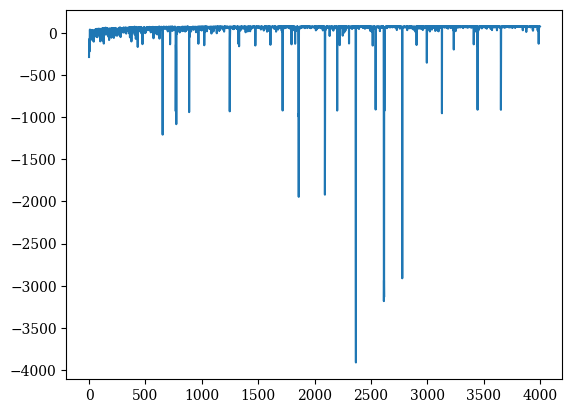

In [28]:

plt.plot(avg_return2)

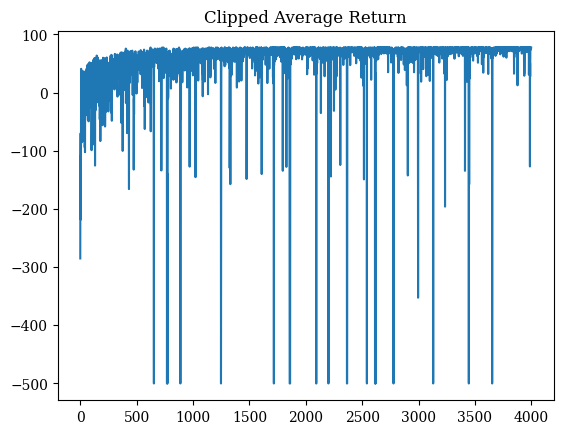

In [29]:
# Define a clipping range
clipped_data2 = np.clip(avg_return2, -500, 500)

# Plot clipped data
plt.plot(clipped_data2)
plt.title("Clipped Average Return")
plt.show()


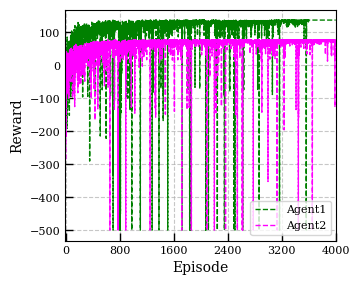

In [30]:
# Apply log scaling
log_data = np.log1p(np.abs(avg_return2)) * np.sign(avg_return2)

# Apply moving average
window_size = 50  # Adjust window size for more/less smoothing
moving_avg = np.convolve(log_data, np.ones(window_size)/window_size, mode='valid')

# Set plot size (width, height in inches)
plt.figure(figsize=(3.5, 3))

# Set font to Times New Roman
plt.rcParams['font.family'] = 'serif'

# Plot log-transformed data with marker
#plt.plot(log_data, linewidth=1,  label="Log-Scaled Reward", color='blue')

# Plot moving average with marker
plt.plot(clipped_data1, linewidth=1,  label="Agent1", linestyle='--', color='green')
plt.plot(clipped_data2, linewidth=1,  label="Agent2", linestyle='--', color='magenta')

# Add labels and legend
plt.xlabel("Episode", fontsize=10)
plt.ylabel("Reward", fontsize=10)
plt.legend(fontsize=8, loc='lower right')

# Adjust x-axis limits to reduce space before 0
plt.xlim(-10, len(log_data)+10) 

# Add x-axis ticks with steps
plt.xticks(np.arange(0, 4200, 800), fontsize=8)  # Adjust the step size as needed
plt.yticks(fontsize=8)  # Adjust the step size as needed
# Add grid
plt.grid(visible=True, linestyle='--', alpha=0.7)

# Add ticks inside the plot
plt.tick_params(axis='both', direction='in', length=6, width=1)

plt.savefig("reward_vs_epsidoe_45 node.png", dpi=600, bbox_inches='tight')


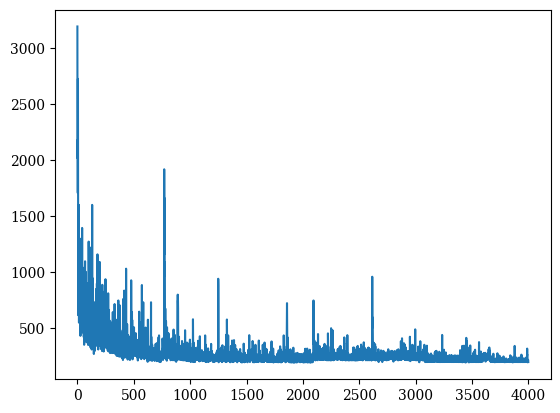

In [31]:
plt.plot(all_cost2)

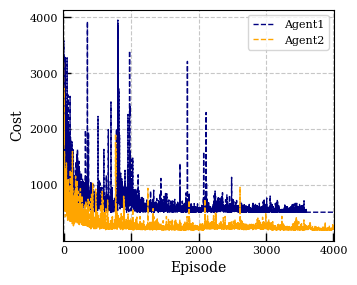

In [32]:
# Apply log scaling
log_data = np.log1p(np.abs(avg_return2)) * np.sign(avg_return2)

# Apply moving average
window_size = 50  # Adjust window size for more/less smoothing
moving_avg = np.convolve(log_data, np.ones(window_size)/window_size, mode='valid')

# Set plot size (width, height in inches)
plt.figure(figsize=(3.5, 3))

# Set font to Times New Roman
plt.rcParams['font.family'] = 'serif'

# Plot log-transformed data with marker
#plt.plot(log_data, linewidth=1,  label="Log-Scaled Reward", color='blue')

# Plot moving average with marker
# Plot moving average with marker
plt.plot(all_cost1, linewidth=1,  label="Agent1", linestyle='--', color='navy')
plt.plot(all_cost2, linewidth=1,  label="Agent2", linestyle='--', color='orange')


# Add labels and legend
plt.xlabel("Episode", fontsize=10)
plt.ylabel("Cost", fontsize=10)
plt.legend(fontsize=8, loc='upper right')

# Adjust x-axis limits to reduce space before 0
plt.xlim(-10, len(log_data)+10) 

# Add x-axis ticks with steps
plt.xticks(fontsize=8)  # Adjust the step size as needed
plt.yticks(fontsize=8)  # Adjust the step size as needed
# Add grid
plt.grid(visible=True, linestyle='--', alpha=0.7)

# Add ticks inside the plot
plt.tick_params(axis='both', direction='in', length=6, width=1)

plt.savefig("cost_vs_epsidoe_45 node.png", dpi=600, bbox_inches='tight')

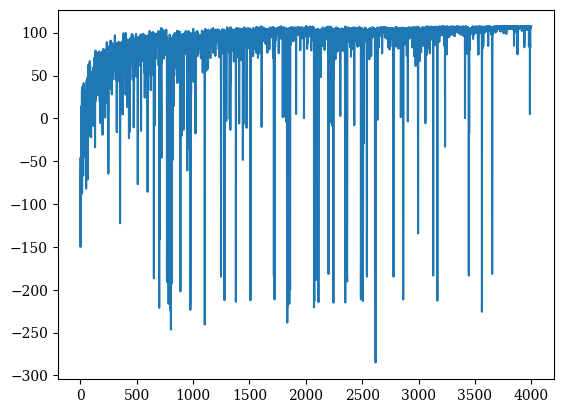

In [35]:
average_reward = (np.array(clipped_data1) + np.array(clipped_data2)) / 2.0
plt.plot(average_reward)
plt.show()
#np.save("rwd-0.000001.npy", average_reward)

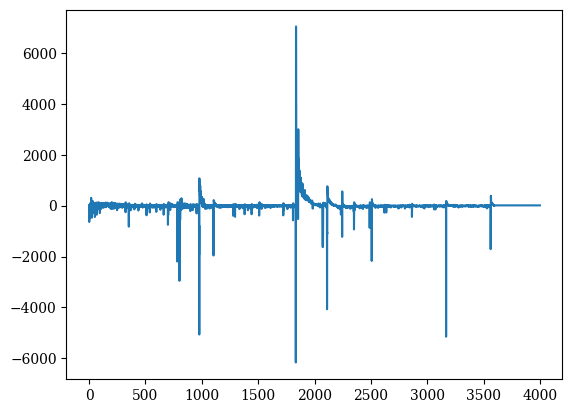

In [73]:
plt.plot(np.array([x.detach().cpu().item() if torch.is_tensor(x) else float(x) for x in avg_a_loss1]))

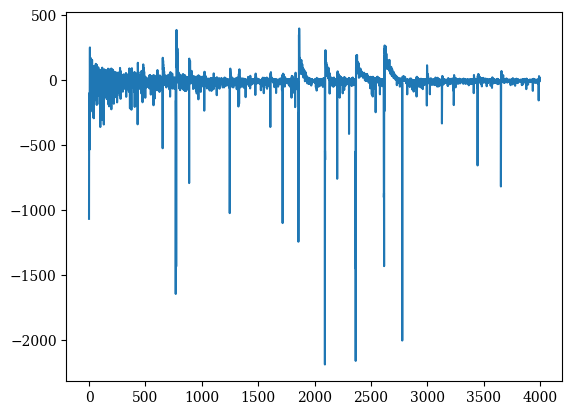

In [74]:
plt.plot(np.array([x.detach().cpu().item() if torch.is_tensor(x) else float(x) for x in avg_a_loss2]))

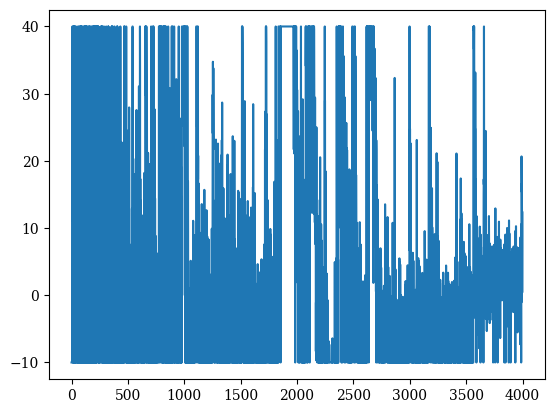

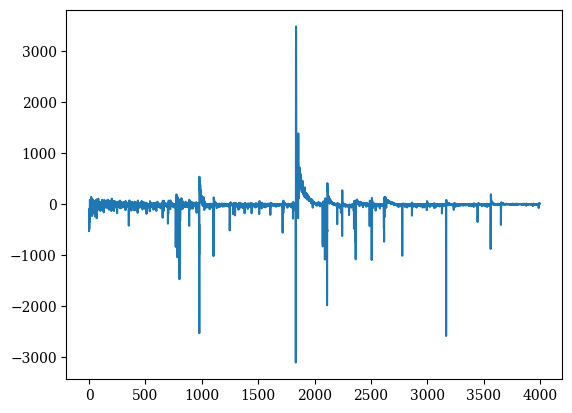

In [70]:
average_a_loss = (
    np.array([x.detach().cpu().item() if torch.is_tensor(x) else float(x) for x in avg_a_loss1]) +
    np.array([x.detach().cpu().item() if torch.is_tensor(x) else float(x) for x in avg_a_loss2])
) / 2.0

# Define a clipping range
clipped_average_a_loss = np.clip(average_a_loss , -10, 40)
# # 2nd-stage clipping only from episode 1500 to 3000
# clipped_average_a_loss[1500:3000] = np.clip(
#     clipped_average_a_loss[1500:3000], -10, 20
# )
#clipped_average_a_loss = np.clip(clipped_average_a_loss[1500:300] , -10, 20)

# Plot clipped data
plt.plot(clipped_average_a_loss)
plt.show()
plt.plot(average_a_loss)
#np.save("loss-0.000001.npy", average_a_loss)

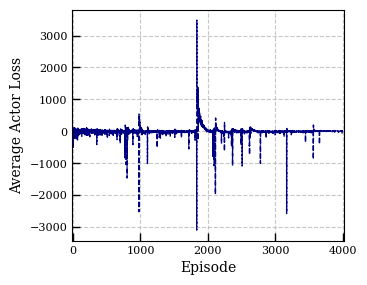

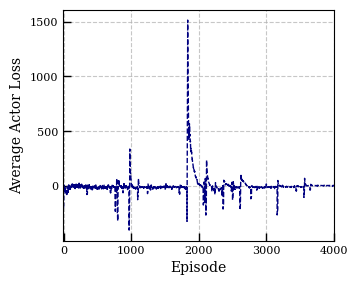

In [57]:
data=average_a_loss

# -------------------------------------------------
# Moving average helper
# -------------------------------------------------
def moving_average(x, window=1000):
    x = np.asarray(x)
    if window <= 1:
        return x
    return np.convolve(x, np.ones(window) / window, mode='valid')

# -------------------------------------------------
# 3. Common plotting style
# -------------------------------------------------
def style_plot():
    plt.rcParams['font.family'] = 'serif'
    plt.xticks(fontsize=8)
    plt.yticks(fontsize=8)
    plt.grid(visible=True, linestyle='--', alpha=0.7)
    plt.tick_params(axis='both', direction='in', length=6, width=1)

# ==========================================================
# 4. RAW CLIPPED AVERAGE ACTOR LOSS vs EPISODE
# ==========================================================
plt.figure(figsize=(3.5, 3))
style_plot()

x = np.arange(len(data))
plt.plot(x, data, linewidth=1, linestyle='--', color='navy')

plt.xlabel("Episode", fontsize=10)
plt.ylabel("Average Actor Loss", fontsize=10)
plt.xlim(-10, len(data) + 10)
plt.show()

# ==========================================================
# 5. MOVING-AVERAGE CLIPPED AVERAGE ACTOR LOSS vs EPISODE
# ==========================================================
window = 10
ma = moving_average(data, window)

plt.figure(figsize=(3.5, 3))
style_plot()

x = np.arange(len(ma))
plt.plot(x, ma, linewidth=1, linestyle='--', color='navy')

plt.xlabel("Episode", fontsize=10)
plt.ylabel("Average Actor Loss", fontsize=10)
plt.xlim(-10, len(ma) + 10)

plt.show()

In [34]:
# ============================================================
# SAVE ALL REUSABLE HA2C TRAINING RESULTS AND MODEL CHECKPOINTS
# Run this block after executing the final-results cell.
# ============================================================

from pathlib import Path
import random
import numpy as np
import torch


OUTPUT_DIRECTORY = Path("ha2c_results_45_nodes")
OUTPUT_DIRECTORY.mkdir(parents=True, exist_ok=True)


# Convert lists containing Python numbers, NumPy values, or PyTorch tensors
# into ordinary NumPy arrays.
def history_to_numpy(history):
    converted_history = []

    for value in history:
        if torch.is_tensor(value):
            value = value.detach().cpu().item()

        converted_history.append(float(value))

    return np.asarray(converted_history, dtype=np.float64)


# Convert a dictionary into a two-column NumPy array.
def integer_mapping_to_array(mapping):
    result = np.empty((len(mapping), 2), dtype=np.int64)

    for index, (key, value) in enumerate(sorted(mapping.items())):
        result[index, 0] = int(key)
        result[index, 1] = int(value)

    return result


# Convert a node-to-latency dictionary into a two-column array.
def latency_mapping_to_array(mapping):
    result = np.empty((len(mapping), 2), dtype=np.float64)

    for index, (key, value) in enumerate(sorted(mapping.items())):
        result[index, 0] = int(key)
        result[index, 1] = float(value)

    return result


# ============================================================
# PREPARE TRAINING HISTORIES
# ============================================================

agent1_cost_history = history_to_numpy(all_cost1)
agent2_cost_history = history_to_numpy(all_cost2)

agent1_reward_history = history_to_numpy(avg_return1)
agent2_reward_history = history_to_numpy(avg_return2)

agent1_actor_loss_history = history_to_numpy(avg_a_loss1)
agent2_actor_loss_history = history_to_numpy(avg_a_loss2)

agent1_critic_loss_history = history_to_numpy(avg_c_loss1)
agent2_critic_loss_history = history_to_numpy(avg_c_loss2)


# ============================================================
# PREPARE FINAL PLACEMENT AND LATENCY RESULTS
# ============================================================

agent1_final_nodes = np.asarray(
    selected_nodes1,
    dtype=np.int64
)

agent2_final_nodes = np.asarray(
    selected_nodes2,
    dtype=np.int64
)

e2_to_g1_array = integer_mapping_to_array(e2_to_g1)
g1_to_g2_array = integer_mapping_to_array(g1_to_g2)

e2_to_g1_latency_array = latency_mapping_to_array(
    agent1_selected_latency
)

g1_worst_first_stage_latency_array = latency_mapping_to_array(
    g1_first_stage_latency
)

loop_results_array = loop_results.to_records(index=False)


# ============================================================
# SAVE NUMERICAL RESULTS, TOPOLOGY DATA, AND CONFIGURATION
# ============================================================

results_file = (
    OUTPUT_DIRECTORY
    / "ha2c_training_results_45_nodes.npz"
)

np.savez_compressed(
    results_file,

    # Agent 1 training histories
    agent1_cost=agent1_cost_history,
    agent1_reward=agent1_reward_history,
    agent1_actor_loss=agent1_actor_loss_history,
    agent1_critic_loss=agent1_critic_loss_history,

    # Agent 2 training histories
    agent2_cost=agent2_cost_history,
    agent2_reward=agent2_reward_history,
    agent2_actor_loss=agent2_actor_loss_history,
    agent2_critic_loss=agent2_critic_loss_history,

    # Final placement decisions
    agent1_selected_nodes=agent1_final_nodes,
    agent2_selected_nodes=agent2_final_nodes,
    active_g1_nodes=np.asarray(
        active_g1_nodes,
        dtype=np.int64
    ),

    # Final associations
    e2_to_g1_association=e2_to_g1_array,
    g1_to_g2_association=g1_to_g2_array,

    # Latency information
    e2_to_g1_latency=e2_to_g1_latency_array,
    g1_worst_first_stage_latency=(
        g1_worst_first_stage_latency_array
    ),
    complete_loop_results=loop_results_array,

    # Topology and state information
    latency_matrix=np.asarray(latency, dtype=np.float64),
    agent1_initial_state=np.asarray(state1, dtype=np.float64),
    agent2_initial_state=np.asarray(state2, dtype=np.float64),
    cloud_nodes=np.asarray(cloud_node, dtype=np.int64),
    regional_nodes=np.asarray(regional_nodes, dtype=np.int64),
    edge_nodes=np.asarray(edge_nodes, dtype=np.int64),
    node_type_encoding=np.asarray(node_encoded, dtype=np.int64),

    # Cost model
    fixed_costs=np.asarray(fixed_costs, dtype=np.float64),
    agent1_variable_costs=np.asarray(
        variable_costs1,
        dtype=np.float64
    ),
    agent2_variable_costs=np.asarray(
        variable_costs2,
        dtype=np.float64
    ),

    # Training configuration
    gamma=np.asarray(gamma, dtype=np.float64),
    learning_rate=np.asarray(lr, dtype=np.float64),
    random_seed=np.asarray(random_seed, dtype=np.int64),
    latency_limit_ms=np.asarray(
        LATENCY_LIMIT_MS,
        dtype=np.float64
    ),
    large_value=np.asarray(LARGE_VALUE, dtype=np.float64),
    total_agent1_episodes=np.asarray(
        TOTAL_EPISODES,
        dtype=np.int64
    ),
    agent1_training_episodes=np.asarray(
        TRAIN_EPISODES,
        dtype=np.int64
    ),
    total_agent2_episodes=np.asarray(
        globals().get("TOTAL_EPISODES_AGENT2", len(avg_return2)),
        dtype=np.int64
    ),
)


# Save the complete-loop result table in a human-readable format.
loop_results.to_csv(
    OUTPUT_DIRECTORY / "ha2c_final_loop_results_45_nodes.csv",
    index=False
)


# ============================================================
# SAVE TRAINED MODELS, OPTIMIZERS, AND RANDOM-NUMBER STATES
# ============================================================

checkpoint_file = (
    OUTPUT_DIRECTORY
    / "ha2c_trained_models_45_nodes.pt"
)

checkpoint = {
    "actor1_state_dict": actor1.state_dict(),
    "critic1_state_dict": critic1.state_dict(),
    "actor2_state_dict": actor2.state_dict(),
    "critic2_state_dict": critic2.state_dict(),

    "optimizerA1_state_dict": optimizerA1.state_dict(),
    "optimizerC1_state_dict": optimizerC1.state_dict(),
    "optimizerA2_state_dict": optimizerA2.state_dict(),
    "optimizerC2_state_dict": optimizerC2.state_dict(),

    "agent1_selected_nodes": agent1_final_nodes,
    "agent2_selected_nodes": agent2_final_nodes,
    "e2_to_g1_association": e2_to_g1,
    "g1_to_g2_association": g1_to_g2,

    "gamma": float(gamma),
    "learning_rate": float(lr),
    "random_seed": int(random_seed),
    "latency_limit_ms": float(LATENCY_LIMIT_MS),
    "large_value": float(LARGE_VALUE),

    # Save RNG states if training needs to be resumed.
    "python_random_state": random.getstate(),
    "numpy_random_state": np.random.get_state(),
    "torch_random_state": torch.get_rng_state(),
    "cuda_random_states": (
        torch.cuda.get_rng_state_all()
        if torch.cuda.is_available()
        else None
    ),
}

torch.save(checkpoint, checkpoint_file)


print(f"Saved numerical results: {results_file}")
print(f"Saved final loop table: {OUTPUT_DIRECTORY / 'ha2c_final_loop_results_45_nodes.csv'}")
print(f"Saved model checkpoint: {checkpoint_file}")

Saved numerical results: ha2c_results_45_nodes/ha2c_training_results_45_nodes.npz
Saved final loop table: ha2c_results_45_nodes/ha2c_final_loop_results_45_nodes.csv
Saved model checkpoint: ha2c_results_45_nodes/ha2c_trained_models_45_nodes.pt
